# Map Projections

Brendan Harmon  
2026-09-12

<figure>
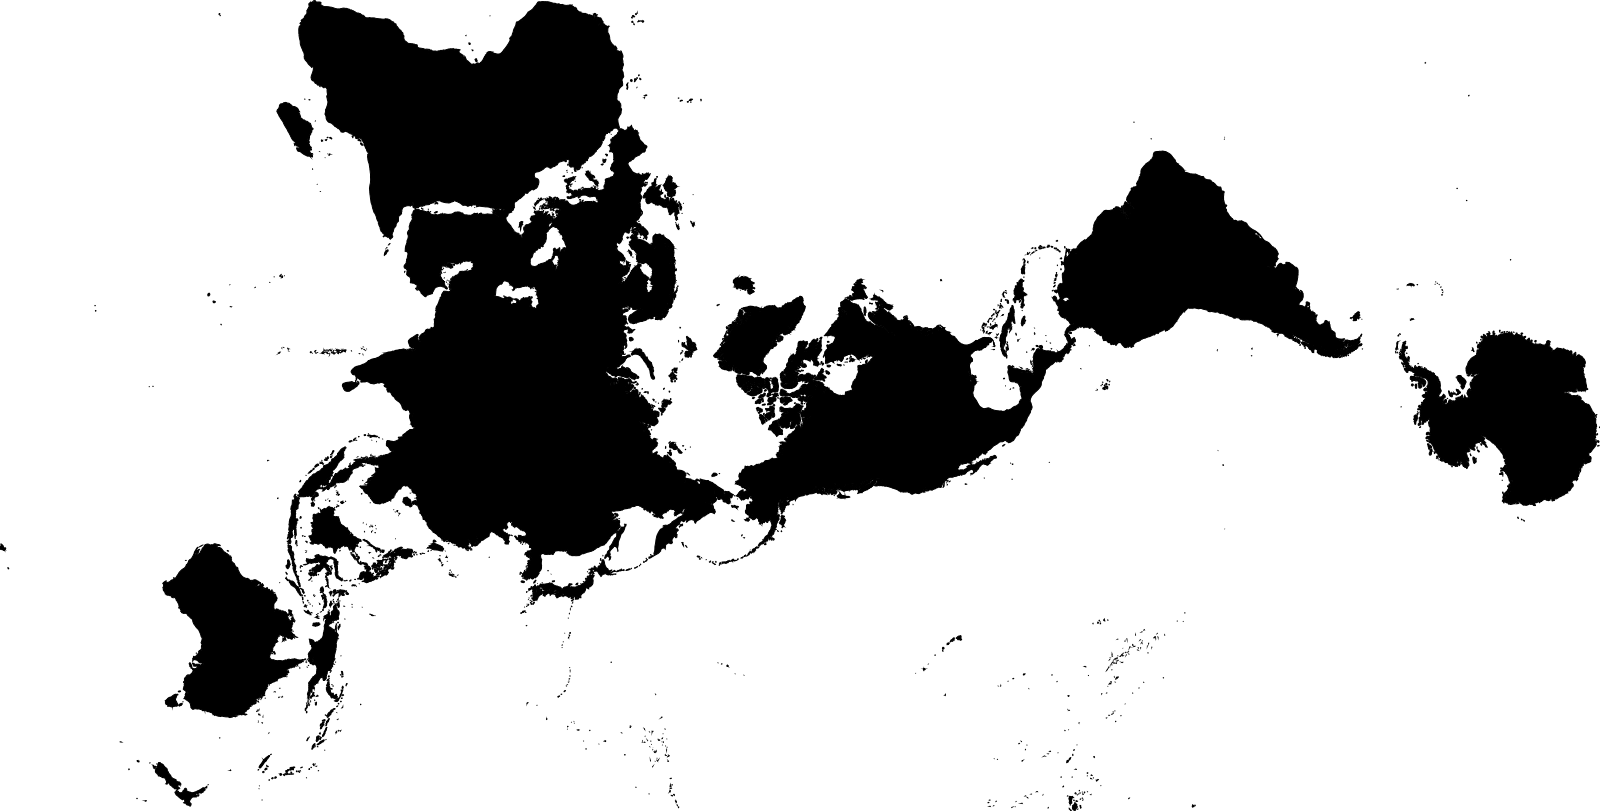
<figcaption aria-hidden="true">Airocean</figcaption>
</figure>

## Setup

In [1]:
# Import libraries
import io
import sys
import subprocess
from pathlib import Path
import requests
from zipfile import ZipFile
import functools
import shutil

# Find GRASS Python packages
sys.path.append(
  subprocess.check_output(
    ["grass", "--config", "python_path"],
    text=True
    ).strip()
  )

# Import GRASS packages
import grass.jupyter as gj
import grass.script as gs
from grass.tools import Tools

## Download land

[Natural Earth](https://www.naturalearthdata.com/)

(Kelso and Patterson 2010)

In [2]:
# Set url
url = "https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip"

# Set path
data = Path.cwd() / "data"
data.mkdir(exist_ok=True)
land = data / Path(url).name

# Download dataset
request = requests.get(url, allow_redirects=True)
if request.status_code != 200:
    raise ConnectionError(f"Error downloading file: {request.status_code}")
land.write_bytes(request.content)
print(land)

# Unarchive dataset
with ZipFile(land, 'r') as archive:
    archive.extractall(path=land.parent)

# Delete archive
land.unlink()

## Download graticules

[Natural Earth](https://www.naturalearthdata.com/)

In [3]:
# Set url
url = "https://naciscdn.org/naturalearth/10m/physical/ne_10m_graticules_15.zip"

# Set path
data = Path.cwd() / "data"
data.mkdir(exist_ok=True)
graticules = data / Path(url).name

# Download dataset
request = requests.get(url, allow_redirects=True)
if request.status_code != 200:
    raise ConnectionError(f"Error downloading file: {request.status_code}")
graticules.write_bytes(request.content)
print(graticules)

# Unarchive dataset
with ZipFile(graticules, 'r') as archive:
    archive.extractall(path=graticules.parent)

# Delete archive
graticules.unlink()

## Natural Earth II

[Natural Earth
II](https://proj.org/en/stable/operations/projections/natearth2.html)

(Šavrič et al. 2015)

In [4]:
# Start GRASS in Natural Earth II project
gs.create_project("natural_earth", epsg=54078, overwrite=True)
session = gj.init("natural_earth")
tools = Tools()

# Import natural earth vector
tools.v_import(input=land.with_suffix(".shp"), output="land")

# Print projection information
tools.g_proj(format="shell", flags="p").text

In [5]:
# Display projection
m = gj.Map(width=800)
m.d_vect(map="land", color="black", fill="black")
m.d_grid(size=15, color="black", flags="gbt")
m.show()

<figure>
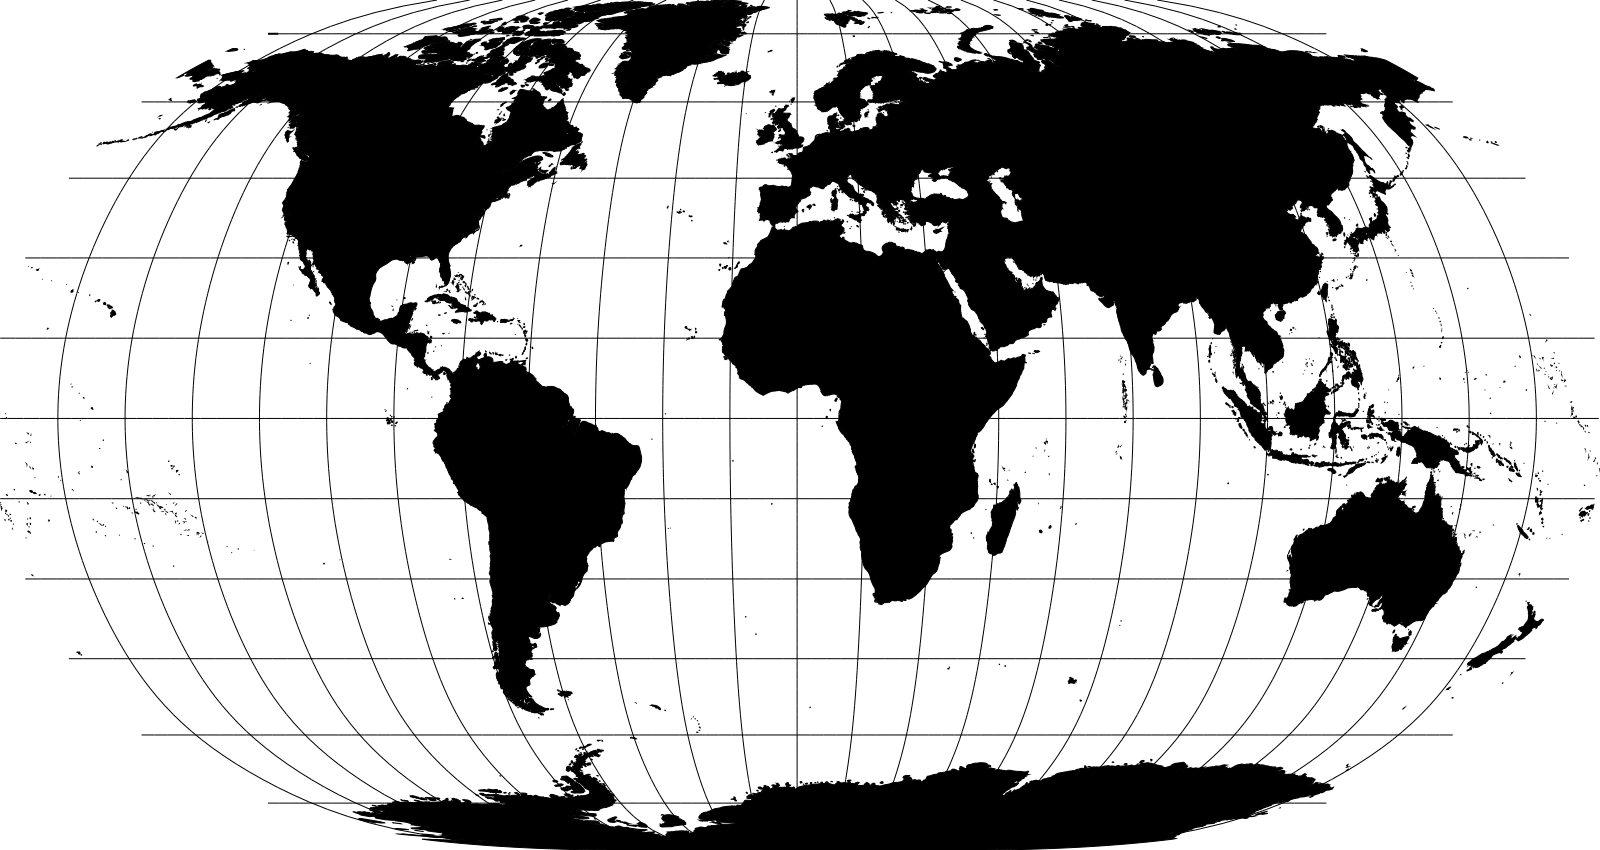
<figcaption aria-hidden="true">Natural Earth II</figcaption>
</figure>

## Equal Earth

[Equal
Earth](https://proj.org/en/stable/operations/projections/eqearth.html)

(Šavrič et al. 2019)

In [6]:
# Create Equal Earth project
tools.g_proj(proj4="+proj=eqearth +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs +type=crs", project="equal_earth")

In [7]:
# Start GRASS in Equal Earth project
session = gj.init("equal_earth")
tools = Tools()

# Import natural earth vector
tools.v_import(input=land.with_suffix(".shp"), output="land") # epsg="4326", , flags="o"

# Print projection information
tools.g_proj(format="shell", flags="p").text

In [8]:
# Display projection
m = gj.Map(width=800)
m.d_vect(map="land", color="black", fill="black")
m.d_grid(size=15, color="black", flags="gbt")
m.show()

<figure>
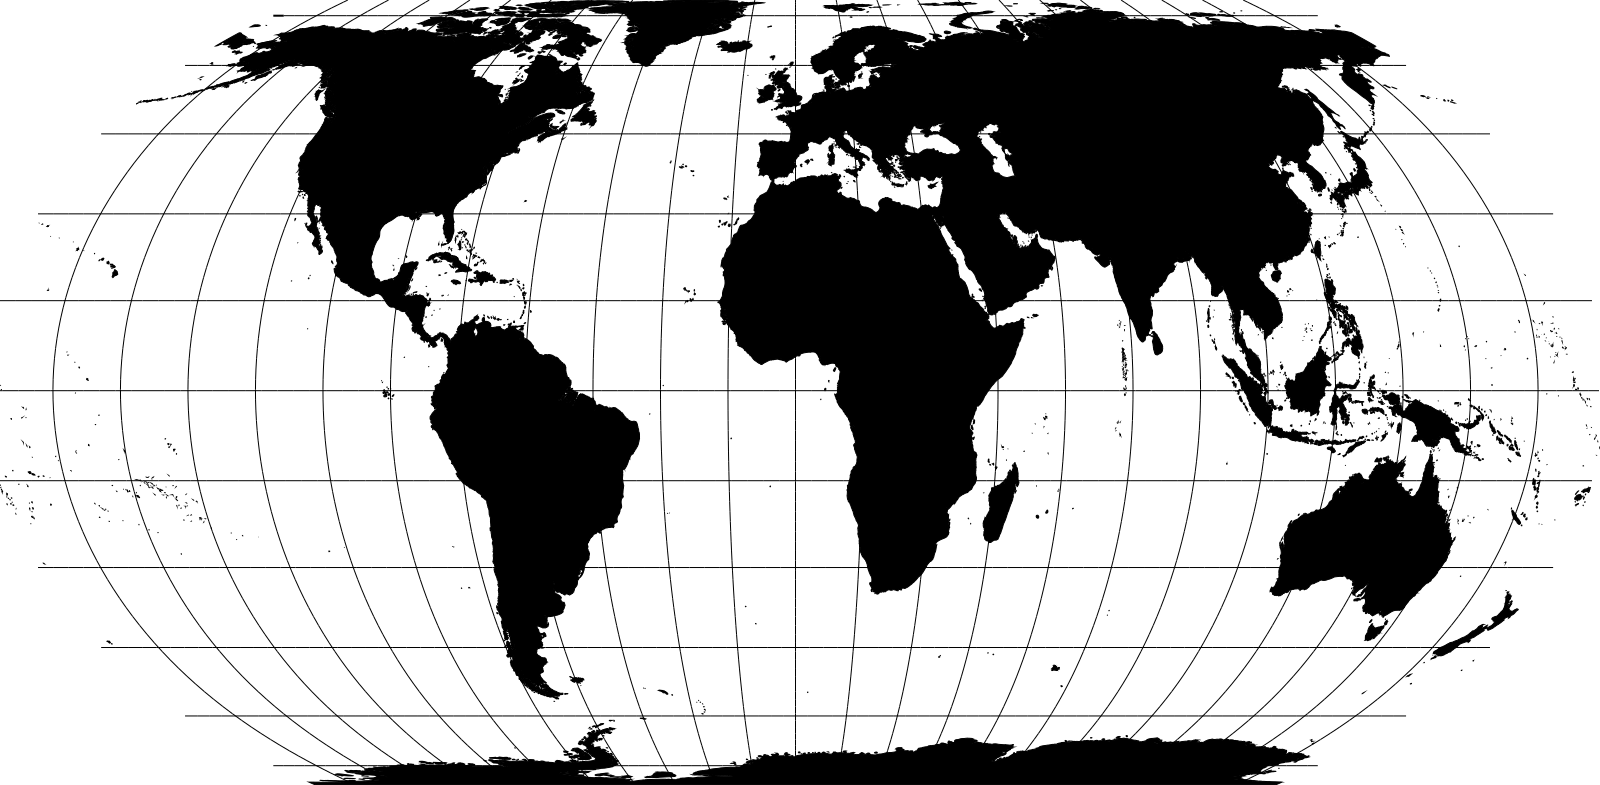
<figcaption aria-hidden="true">Equal Earth</figcaption>
</figure>

## Airocean

[Airocean](https://proj.org/en/stable/operations/projections/airocean.html)

(Gray 1995)

In [9]:
# Create Airocean project
tools.g_proj(proj4="+proj=airocean +orient=horizontal +lon_0=0.0 +x_0=0.0 +y_0=0.0 +datum=WGS84 +type=crs", project="airocean") # vertical

In [10]:
# Start GRASS in Airocean project
session = gj.init("airocean")
tools = Tools()

# Import natural earth vector
tools.v_import(input=land.with_suffix(".shp"), output="land")

# Print projection information
tools.g_proj(format="shell", flags="p").text

In [11]:
# Display projection
m = gj.Map(width=800)
m.d_vect(map="land", color="black", fill="black")
m.show()

<figure>
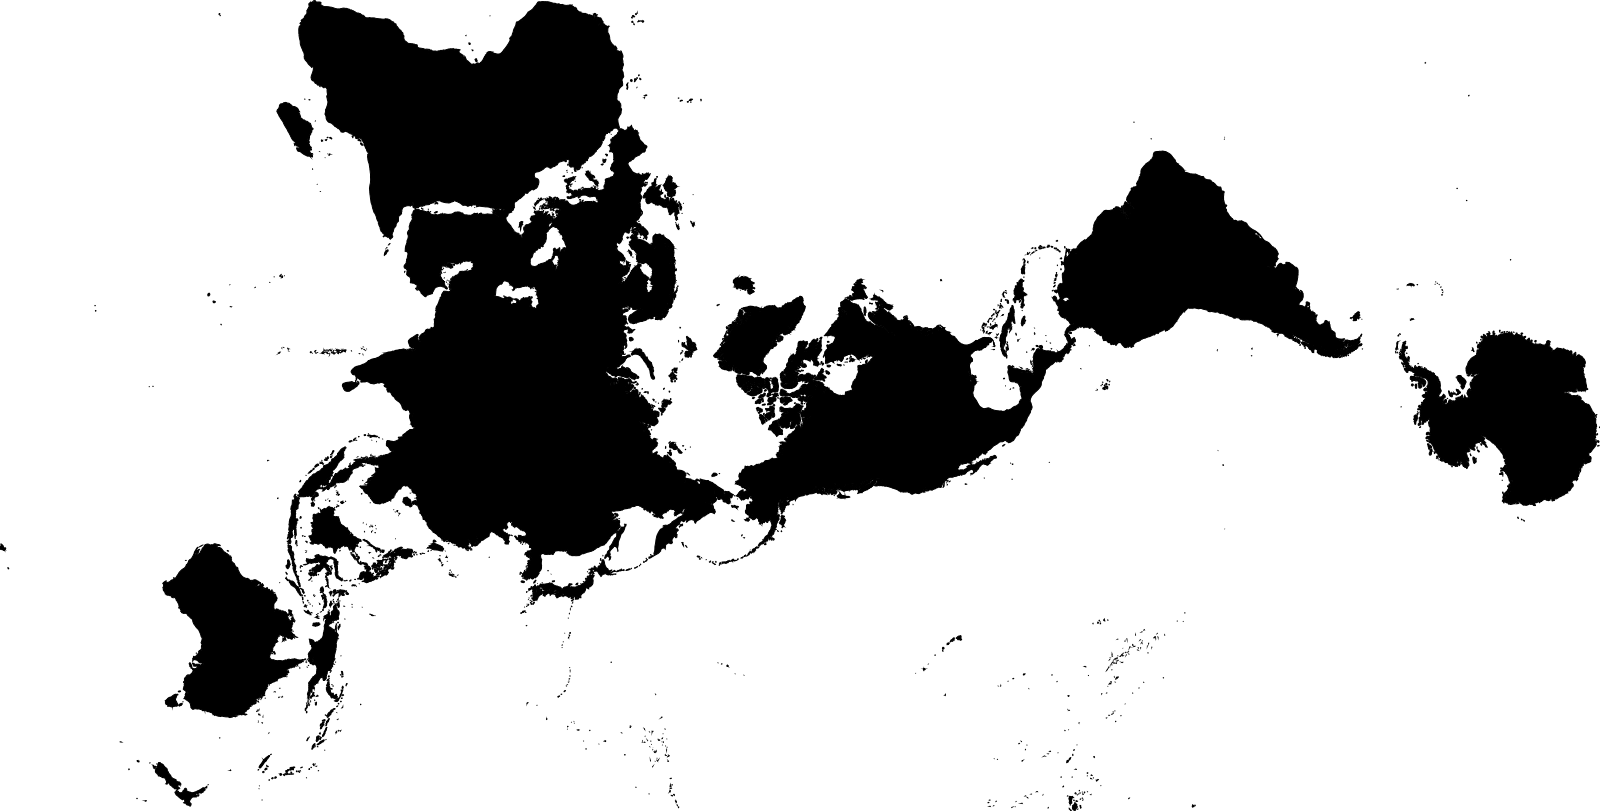
<figcaption aria-hidden="true">Airocean</figcaption>
</figure>

## Peirce Quincuncial

[Peirce
Quincuncial](https://proj.org/en/stable/operations/projections/peirce_q.html)

In [12]:
# Create Peirce Quincuncial project
tools.g_proj(proj4="+proj=peirce_q +lon_0=25 +shape=square +datum=WGS84 +type=crs", project="peirce_quincuncial") # +shape=diamond

In [13]:
# Start GRASS in Peirce Quincuncial project
session = gj.init("peirce_quincuncial")
tools = Tools()

# Import land
tools.v_import(input=land.with_suffix(".shp"), output="land")

# Import graticules
tools.v_import(input=graticules.with_suffix(".shp"), output="graticules")

# Print projection information
tools.g_proj(format="shell", flags="p").text

In [14]:
# Display projection
m = gj.Map(width=800)
m.d_vect(map="land", color="black", fill="black")
m.d_vect(map="graticules", color="black", fill="none")
m.show()

<figure>
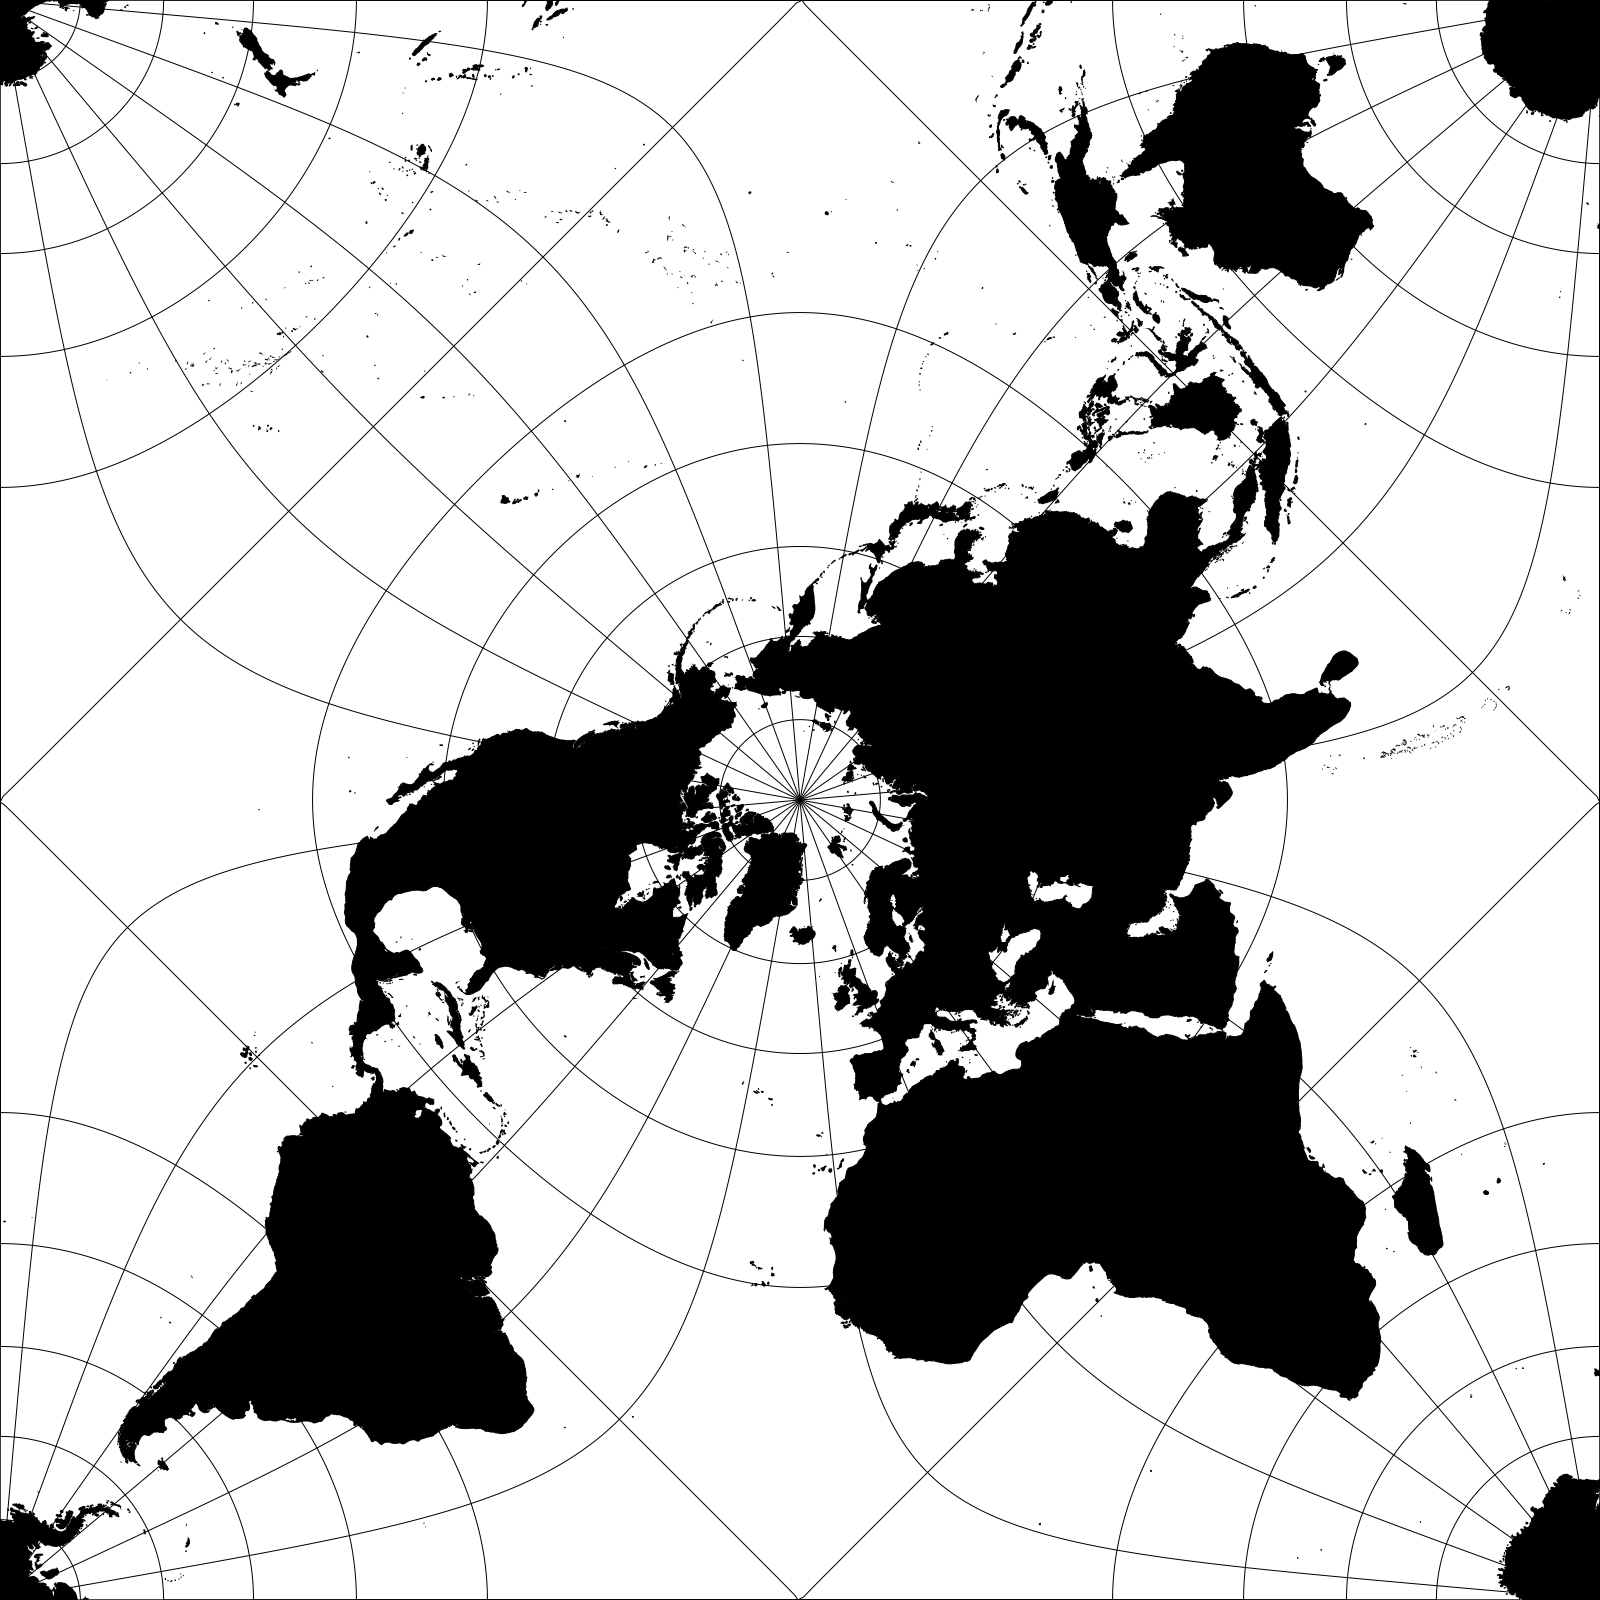
<figcaption aria-hidden="true">Peirce Quincuncial</figcaption>
</figure>

## van der Grinten IV

[van der Grinten
IV](https://proj.org/en/stable/operations/projections/vandg4.html)

In [15]:
# Create van der Grinten IV project
tools.g_proj(proj4="+proj=vandg4 +datum=WGS84 +type=crs", project="vandg4")

In [16]:
# Start GRASS in van der Grinten IV project
session = gj.init("vandg4")
tools = Tools()

# Import land
tools.v_import(input=land.with_suffix(".shp"), output="land")

# Print projection information
tools.g_proj(format="shell", flags="p").text

In [17]:
# Display projection
m = gj.Map(width=800)
m.d_vect(map="land", color="black", fill="black")
m.show()

<figure>
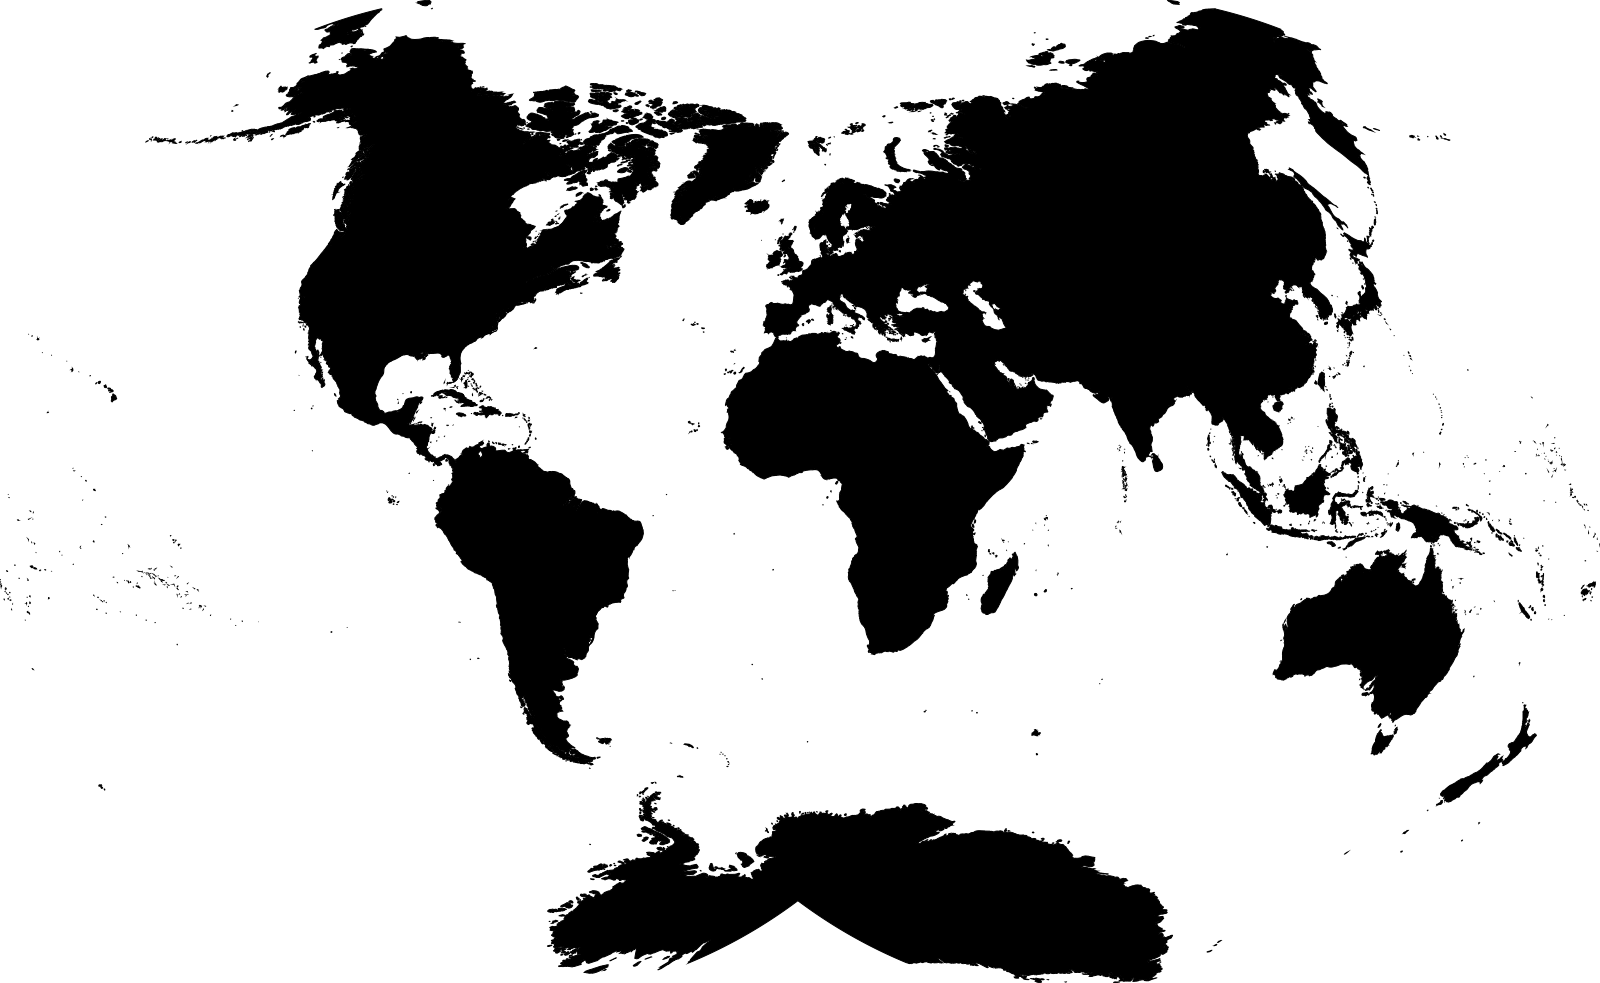
<figcaption aria-hidden="true">van der Grinten IV</figcaption>
</figure>

Gray, Robert W. 1995. “Exact Transformation Equations for
<span class="nocase">Fuller’s</span> World Map.” *Cartographica* 32 (3):
17–25. <https://doi.org/10.3138/1677-3273-Q862-1885>.

Kelso, Nathaniel Vaughn, and Tom Patterson. 2010. “Introducing Natural
Earth Data.” *Geographia Technica* 5 (1): 82–89.

Šavrič, Bojan, Tom Patterson, and Bernhard Jenny. 2015. “The Natural
Earth II World Map Projection.” *International Journal of Cartography* 1
(2): 123–33. <https://doi.org/10.1080/23729333.2015.1093312>.

Šavrič, Bojan, Tom Patterson, and Bernhard Jenny. 2019. “The Equal Earth
Map Projection.” *International Journal of Geographical Information
Science* 33 (3): 454–65.
<https://doi.org/10.1080/13658816.2018.1504949>.